# LUMA - Lokalny Urok Mistrzostwa Artystycznego
LUMA to lokalny jarmark, który rośnie z tygodnia na tydzień: coraz więcej wystawców, więcej gości (miejscowych i turystów), okazjonalne promocje i sezonowość.

# Import bibliotek

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Wygenerowanie syntetycznych danych

### Ustawienie ziarna RNG

In [16]:
RNG_seed = 20261020
rng = np.random.default_rng(RNG_seed)
print("Ustawiono ziarno RNG: ", RNG_seed)

Ustawiono ziarno RNG:  20261020


## Zdefiniowanie "Stałych"

In [17]:
LUMA_FULL = "Lokalny Urok Mistrzowtwa Artystycznego"
KATEGORIE = ["Ceramika", "Tekstylia", "Biżuteria", "Rękodzieło", "Przetwory", "Dekoracje", "Stolarka", "Masarstwo", "Alkohole"]

### Przygotowanie bazowych danych syntetycznych

"Katalog" kategorii i ich bazowe parametry generatywne (syntytyczne) 


In [18]:
catalog = pd.DataFrame({
    "category": KATEGORIE,
    "demand_loc_base": [120, 180, 130, 80, 160, 150, 70, 90 ,110], # średni lokalny popyt (szt./tydz.)
    "demand_tur_base": [60, 40, 80, 30, 90, 30, 50, 40, 80], # średni popyt turystyczny (szt./tydz.)
    "price_pln_base": [8, 120, 150, 230, 40, 35, 250, 215, 135] # średnia cena jednostkowa
})

### Wyliczony "typowy" przychód tygodniowy

In [19]:
catalog["revenue_avg_pln"] = (catalog["demand_loc_base"] + catalog["demand_tur_base"])* catalog["price_pln_base"]

In [ ]:
catalog

### Przygotowanie funkcji pomocniczych do generowania danych tygodniowych

Generowanie popytu lokalnego i turystycznego na podstawie danych bazowych, z losowym szumem i opcjonalnymi boostami

In [20]:
def determine_demand(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    df = catalog[["category", "demand_loc_base", "demand_tur_base"]].copy()
    eps_loc = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    eps_tur = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    df["demand_loc"] = (df["demand_loc_base"] * (1 + boost_loc)) * eps_loc
    df["demand_tur"] = (df["demand_tur_base"] * (1 + boost_tur)) * eps_tur 
    df["demand_loc"] = np.maximum(df["demand_loc"].round().astype(int), 0)
    df["demand_tur"] = np.maximum(df["demand_tur"].round().astype(int), 0)
    return df[["category", "demand_loc", "demand_tur"]]
   

Wyliczanie przychodu lokalnego, turystycznego i łącznego

In [21]:
def count_revenue(catalog, demand_df):
    df = demand_df.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
    df["revenue_loc"] = df["demand_loc"] * df["price_pln_base"]
    df["revenue_tur"] = df["demand_tur"] * df["price_pln_base"]
    df["revenue_pln"] = df["revenue_loc"] + df["revenue_tur"]
    return df[["category", "revenue_loc", "revenue_tur", "revenue_pln"]]


Generowanie danych tygodniowych

In [22]:
def generate_weekly_data(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    demand_df = determine_demand(catalog, rng, variance=variance, boost_loc=boost_loc, boost_tur=boost_tur)
    revenue_df = count_revenue(catalog, demand_df)
    return revenue_df

Wygenerowanie danych tygodniowych

In [23]:
t1 = generate_weekly_data(catalog, rng)
t1 = t1.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
print("Tydzień 1 - przychody per kategoria (PLN)")
display(t1)
print("Łączny przychód w tygodniu 1 (PLN): ", t1["revenue_pln"].sum())

Tydzień 1 - przychody per kategoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,Ceramika,688,392,1080,8
1,Tekstylia,21240,3360,24600,120
2,Biżuteria,13350,11700,25050,150
3,Rękodzieło,22540,6440,28980,230
4,Przetwory,7720,3680,11400,40
5,Dekoracje,4900,1120,6020,35
6,Stolarka,19000,14250,33250,250
7,Masarstwo,18275,8815,27090,215
8,Alkohole,18630,10260,28890,135


Łączny przychód w tygodniu 1 (PLN):  186360


# Analiza i wizualizacja danych

Podstawowe wykresy

<Axes: >

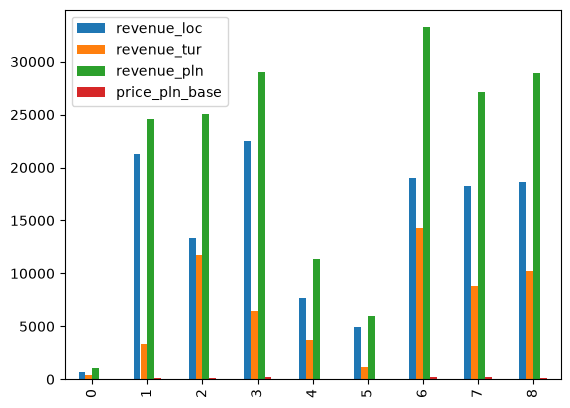

In [24]:
t1.plot.bar()

In [ ]:
t1[["revenue_loc", "revenue_tur"]].plot.bar()

In [ ]:
t1[["revenue_loc", "revenue_tur"]].plot.barh(stacked=True)

Minimalny wykres

<BarContainer object of 9 artists>

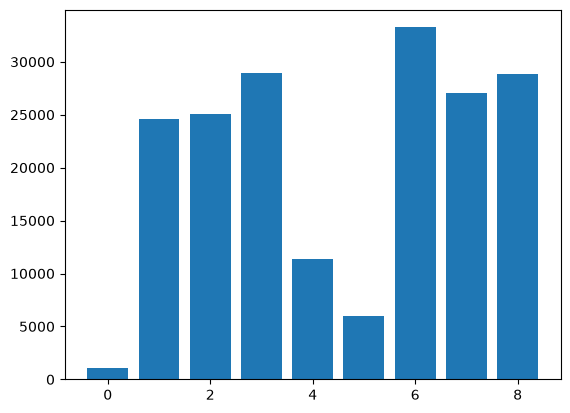

In [27]:
heights = t1["revenue_pln"]
plt.bar(range(len(heights)), heights)

In [30]:
heights = t1["revenue_pln"]
categories = t1["category"]

In [29]:
plt.figure(figsize=(8, 4))
plt.bar(categories, heights)
plt.show()

NameError: name 'categories' is not defined

<Figure size 800x400 with 0 Axes>

Jawne tworzenie i wyświetlanie wykresu

In [28]:
plt.figure(figsize=(12, 4))
plt.bar(categories, heights)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.show()

NameError: name 'categories' is not defined

<Figure size 1200x400 with 0 Axes>

Etykiety wartości i formatowanie liczb

In [31]:
def format_pln(x: float) -> str:
    return f"{int(round(x)):,} zł".replace(",","\u202f")

In [ ]:
print(format_pln(12345.789))

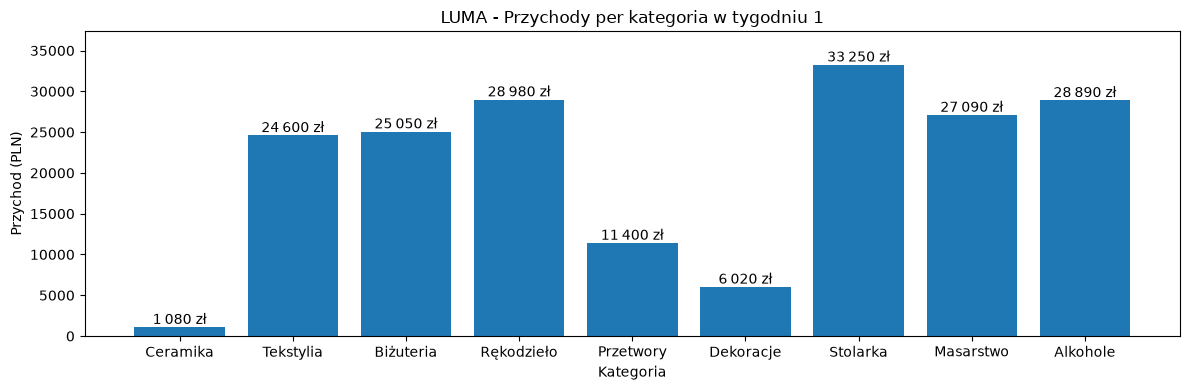

In [34]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
ymin, ymax = plt.ylim()
pad = (ymax-ymin)*0.07
plt.ylim(ymin, ymax + pad)
for bar in bars:
    x = bar.get_x() + bar.get_width() / 2
    y = bar.get_height()
    plt.text(x, y, format_pln(y), ha="center", va = "bottom")
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychod (PLN)")
plt.tight_layout()
plt.show()

In [35]:
def pad_axis(factor=0.07):
    ymin, ymax = plt.ylim()
    pad = (ymax-ymin)*0.07
    plt.ylim(ymin, ymax + pad)

In [36]:
def label_bars_pln(bars):
    for bar in bars:
        x = bar.get_x() + bar.get_width() / 2
        y = bar.get_height()
        plt.text(x, y, format_pln(y), ha="center", va = "bottom")

Formatowanie  etykiet podziałki osi 

In [46]:
def format_tys(x: float, decimals: int=0) -> str:
    y = x/ 1000.0
    if decimals == 0:
        s = f"{int(round(x))}".replace(",","\u202f")
    else:
        s = f"{y:.{decimals}f}".replace(",","\u202f").replace(".",",")
    return s + " tys."

In [ ]:
def format_mln(x: float, decimals: int=0) -> str:
    y = x/ 1000000.0
    if decimals == 0:
        s = f"{int(round(x))}".replace(",","\u202f")
    else:
        s = f"{y:.{decimals}f}".replace(",","\u202f").replace(".",",")
    return s + " mln."

In [48]:
print(format_mln(1234567.89))
print(format_tys(1234567.89))

1234568 mln.
1234568 tys.


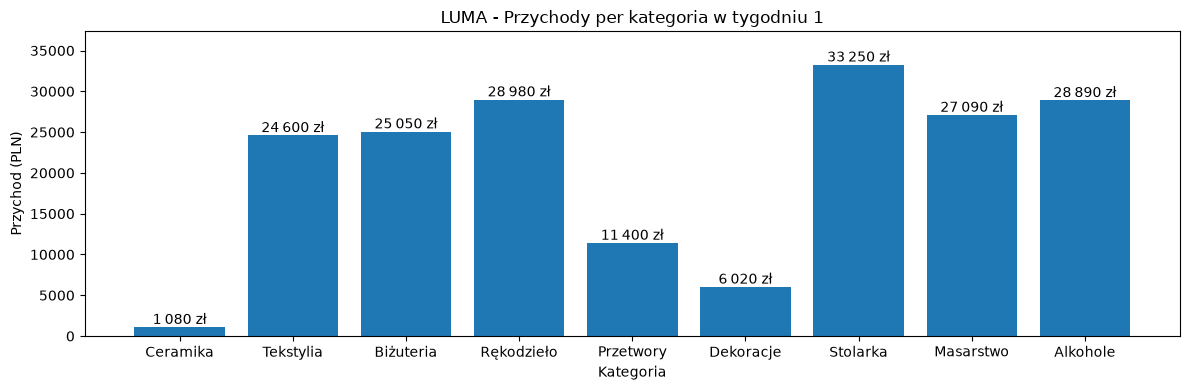

In [37]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
pad_axis()
label_bars_pln(bars)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychod (PLN)")
plt.tight_layout()
plt.show()